#Deep Learning para visión de computadoras
##Lab 2.2 Segmentación semántica

Colab: https://colab.research.google.com/drive/1T0PKmEHPkEJBPbWV9ZYVs1Jtn_s9vWII?usp=sharing

GitHub: https://github.com/josue-mtz/Deeplearning-para-vision-por-computadoras

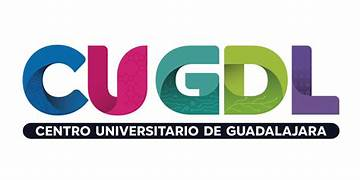

# Objetivo
Calcular IoU por clase y mIoU a mano a partir de la matriz de confusión y verificar con torchmetrics.
Construir una U-Net desde cero y medir qué aportan las conexiones de salto.
Comparar tres funciones de pérdida: entropía cruzada, Dice y su combinación.
Secuencias de video: CNN estática vs. CNN-LSTM

In [1]:
%pip install -q torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 54.8 MB/s eta 0:00:00


In [2]:
import time, copy
import os
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader, Dataset, Subset
import torchmetrics
import torchvision
import torchvision.transforms as T
from torchmetrics.classification import MulticlassJaccardIndex, MulticlassConfusionMatrix

SEED = 2
def fijar_semilla(s=SEED):
    np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
fijar_semilla()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", DEVICE, "·", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU (más lento, pero funciona)")
print("torch", torch.__version__, "· torchmetrics", torchmetrics.__version__)

NOMBRES = ["fondo", "círculo", "cuadrado", "triángulo"]
N_CLASES = len(NOMBRES)
TAM = 64                       # las imágenes son de 64 x 64 píxeles

Dispositivo: cuda · Tesla T4
torch 2.11.0+cu130 · torchmetrics 1.9.0


---
# PARTE A

En clasificación, una imagen tiene **una** etiqueta. En segmentación semántica, una imagen de $H\times W$ tiene **$H\cdot W$ etiquetas**:

El conjunto de datos de mascotas Oxford- IIIT ( Parkhi et al, 2012 ). El conjunto de datos consta de imágenes de 37 razas de mascotas, con 200 imágenes por raza (~100 cada una en las divisiones de entrenamiento y prueba). Cada imagen incluye las etiquetas correspondientes y las máscaras de píxeles.

    El dataset contiene imágenes de mascotas y máscaras de segmentación de 3 clases:
    
    Clase 1: Mascota (Foreground)
    Clase 2: Fondo (Background)
    Clase 3: Borde / Contorno ambiguo\

In [3]:
TAM = 128
NOMBRES_CLASES = ["Mascota", "Fondo", "Borde"]
N_CLASES = len(NOMBRES_CLASES)

# Transformación para la imagen (RGB -> Normalización estándar de ImageNet)
transform_img = T.Compose([
    T.Resize((TAM, TAM)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Transformación para la máscara (Interpolación NEAREST para preservar enteros) reescalado, garantizando que no se generen valores intermedios artificiales entre categorías.
#Por conveniencia, reste 1 de la máscara de segmentación, lo que da como resultado etiquetas que son: {0, 1, 2}.
def transform_mask(mask):
    mask = mask.resize((TAM, TAM), resample=Image.NEAREST)
    mask_arr = np.array(mask, dtype=np.int64) - 1  # Pasar de {1,2,3} a {0,1,2}
    return torch.as_tensor(mask_arr, dtype=torch.long)

# Descargar dataset oficial vía torchvision
train_raw = torchvision.datasets.OxfordIIITPet(
    root="./data", split="trainval", target_types="segmentation", download=True,
    transform=transform_img, target_transform=transform_mask
)
test_raw = torchvision.datasets.OxfordIIITPet(
    root="./data", split="test", target_types="segmentation", download=True,
    transform=transform_img, target_transform=transform_mask
)

# Subconjuntos optimizados para una sesión interactiva de clase (rápida convergencia)
train_ds = Subset(train_raw, range(1000))
val_ds = Subset(test_raw, range(250))

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=16, shuffle=False, num_workers=2)

print(f"Imágenes de entrenamiento: {len(train_ds)} | Validación: {len(val_ds)}")

100%|██████████| 792M/792M [00:38<00:00, 20.6MB/s]
100%|██████████| 19.2M/19.2M [00:02<00:00, 9.25MB/s]


Imágenes de entrenamiento: 1000 | Validación: 250


máscaras reales codificadas mediante un mapa de color cualitativo (Verde = Mascota, Negro = Fondo, Rojo = Borde):

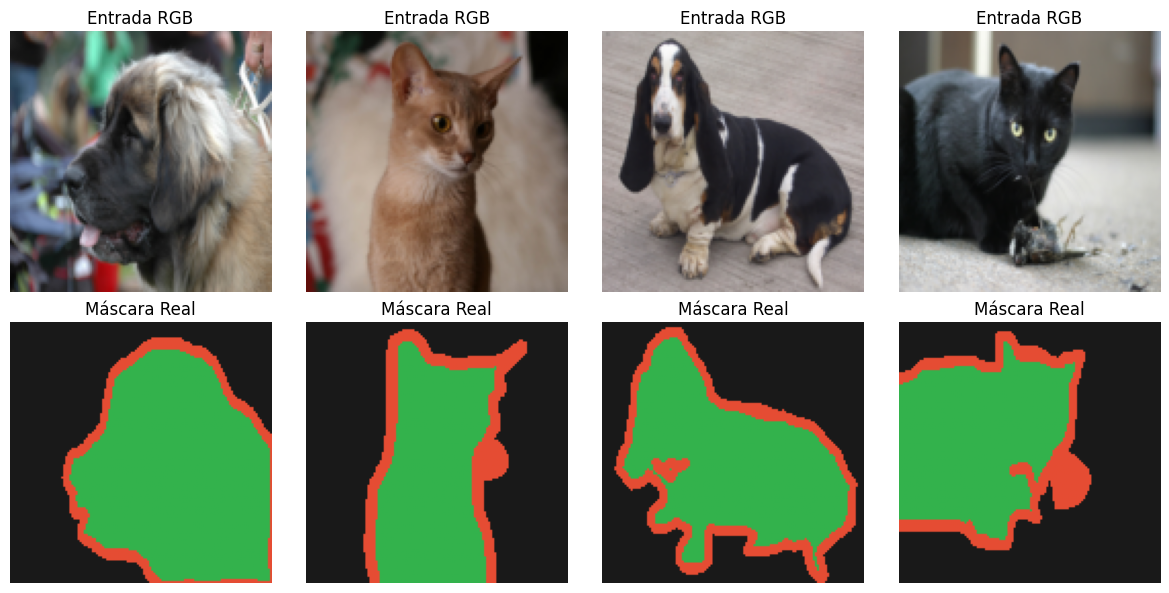

In [4]:
def desnormalizar(tensor):
    img = tensor.clone().cpu().permute(1, 2, 0).numpy()
    img = img * [0.229, 0.224, 0.225] + [0.485, 0.456, 0.406]
    return np.clip(img, 0, 1)

PALETA_PETS = np.array([[0.2, 0.7, 0.3], [0.1, 0.1, 0.1], [0.9, 0.3, 0.2]])

imgs, masks = next(iter(train_loader))
fig, axs = plt.subplots(2, 4, figsize=(12, 6))
for i in range(4):
    axs[0, i].imshow(desnormalizar(imgs[i]))
    axs[0, i].set_title("Entrada RGB")
    axs[0, i].axis("off")

    axs[1, i].imshow(PALETA_PETS[masks[i].numpy()])
    axs[1, i].set_title("Máscara Real")
    axs[1, i].axis("off")
plt.tight_layout()
plt.show()

# 2. ARQUITECTURA DE LA RED: U-NET COMPACTA DESDE CEROLa red implementa una estructura simétrica compuesta por:   

1.   Bloque Doble de Convolución: Encapsula la secuencia $\text {Conv2D} \rightarrow \text{BatchNorm} \rightarrow \text{ReLU}$ por duplicado, manteniendo dimensiones espaciales mediante relleno (padding $= 1$).

2.   Trayectoria de Contracción (Encoder): Reduce periódicamente la resolución a la mitad con operaciones de agrupamiento máximo (MaxPool2d) mientras incrementa la profundidad de canales semánticos.   
3. Cuello de Botella (Bottleneck): El punto de mayor compresión espacial ($16 \times 16$) y máxima abstracción de características.   
4. Trayectoria de Expansión (Decoder): Aplica convoluciones transpuestas (ConvTranspose2d) con factor de escala $\times 2$ y realiza la fusión por concatenación (torch.cat) de las activaciones correspondientes del codificador.   
5. Capa de Salida: Una convolución $1 \times 1$ que reduce los 32 canales residuales a 3 logits correspondientes a las clases del problema.  

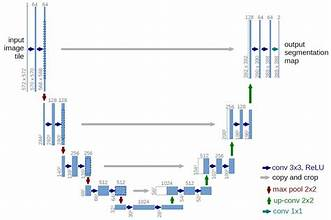

In [5]:
class BloqueDobleConv(nn.Module):
    """(Conv2d -> BatchNorm -> ReLU) * 2"""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.net(x)

class UNetCompacta(nn.Module):
    def __init__(self, in_channels=3, num_classes=3):
        super().__init__()
        # --- ENCODER ---
        self.enc1 = BloqueDobleConv(in_channels, 32)      # Entrada: 128x128
        self.pool1 = nn.MaxPool2d(2, 2)                   # -> 64x64

        self.enc2 = BloqueDobleConv(32, 64)               # -> 64x64
        self.pool2 = nn.MaxPool2d(2, 2)                   # -> 32x32

        self.enc3 = BloqueDobleConv(64, 128)              # -> 32x32
        self.pool3 = nn.MaxPool2d(2, 2)                   # -> 16x16

        # --- BOTTLENECK ---
        self.bottleneck = BloqueDobleConv(128, 256)       # -> 16x16

        # --- DECODER & SKIP CONNECTIONS ---
        self.up3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2) # -> 32x32
        self.dec3 = BloqueDobleConv(256, 128)             # 128 (skip) + 128 = 256

        self.up2 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)   # -> 64x64
        self.dec2 = BloqueDobleConv(128, 64)              # 64 (skip) + 64 = 128

        self.up1 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)    # -> 128x128
        self.dec1 = BloqueDobleConv(64, 32)               # 32 (skip) + 32 = 64

        # Proyección final lineal a nivel de píxel
        self.out_conv = nn.Conv2d(32, num_classes, kernel_size=1)

    def forward(self, x):
        # Paso por el Encoder
        s1 = self.enc1(x)
        p1 = self.pool1(s1)

        s2 = self.enc2(p1)
        p2 = self.pool2(s2)

        s3 = self.enc3(p2)
        p3 = self.pool3(s3)

        # Cuello de botella
        b = self.bottleneck(p3)

        # Paso por el Decoder con Skip Connections (torch.cat)
        d3 = self.up3(b)
        d3 = torch.cat([d3, s3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, s2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, s1], dim=1)
        d1 = self.dec1(d1)

        return self.out_conv(d1)

modelo = UNetCompacta(in_channels=3, num_classes=3).to(DEVICE)
print("Arquitectura instanciada. Parámetros totales:", sum(p.numel() for p in modelo.parameters()))

Arquitectura instanciada. Parámetros totales: 1927075


---
# PARTE B

Sean $TP_c$, $FP_c$, $FN_c$ los píxeles de la clase $c$ acertados, falsamente asignados a $c$ y omitidos, respectivamente. Para cada clase:

$$\mathrm{IoU}_c=\frac{TP_c}{TP_c+FP_c+FN_c}\qquad \mathrm{Dice}_c=\frac{2\,TP_c}{2\,TP_c+FP_c+FN_c}\qquad \mathrm{mIoU}=\frac{1}{C}\sum_{c=1}^{C}\mathrm{IoU}_c$$

Todo sale de la **matriz de confusión** de píxeles: la diagonal contiene los $TP_c$; la suma de la fila $c$ menos la diagonal son los $FN_c$; la suma de la columna $c$ menos la diagonal son los $FP_c$. Aquí las filas son la clase real y las columnas la predicha.

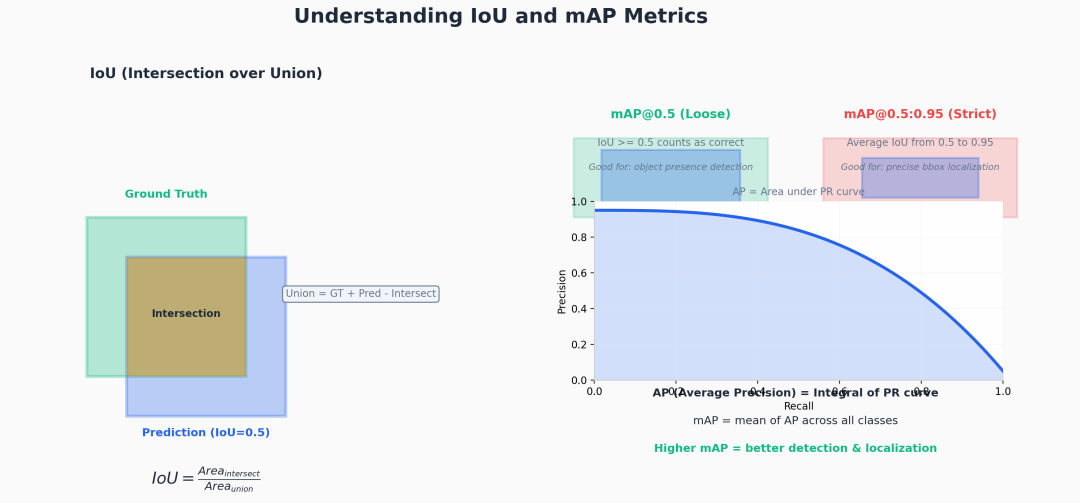

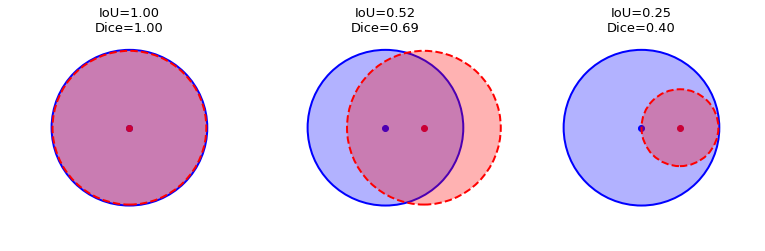

Revisar: https://ilmonteux.github.io/2019/05/10/segmentation-metrics.html


Para optimizar adecuadamente la segmentación semántica frente al desbalance de clases (por ejemplo, el borde contiene considerablemente menos píxeles que el fondo), se combinan dos objetivos complementarios:   

Cross-Entropy Loss ($\mathcal{L}_{\text{CE}}$): Evalúa la distribución de probabilidad generada independientemente en cada posición $(i, j)$ del mapa de píxeles.   

Dice Loss ($\mathcal{L}_{\text{Dice}}$): Mide el solapamiento volumétrico entre la máscara binarizada y la predicción probabilística:

   $$\text{Dice} = \frac{2 \vert{}P \cap T\vert{}}{\vert{}P\vert{} + \vert{}T\vert{}} = \frac{2 \sum p_i t_i}{\sum p_i^2 + \sum t_i^2}$$   Pérdida Híbrida Total:$$\mathcal{L}_{\text{Total}} = \mathcal{L}_{\text{CE}} + \mathcal{L}_{\text{Dice}}$$

In [6]:
class DiceLoss(nn.Module):
    def __init__(self, eps=1e-6):
        super().__init__()
        self.eps = eps

    def forward(self, logits, targets):
        num_classes = logits.shape[1]
        probs = F.softmax(logits, dim=1)

        # One-hot encoding de targets a dimensiones [B, C, H, W]
        targets_one_hot = F.one_hot(targets, num_classes=num_classes).permute(0, 3, 1, 2).float()

        # Aplanar dimensiones espaciales para el cálculo vectorial
        probs = probs.contiguous().view(probs.shape[0], num_classes, -1)
        targets_one_hot = targets_one_hot.contiguous().view(targets_one_hot.shape[0], num_classes, -1)

        interseccion = (probs * targets_one_hot).sum(dim=2)
        union = probs.sum(dim=2) + targets_one_hot.sum(dim=2)

        dice = (2. * interseccion + self.eps) / (union + self.eps)
        return 1.0 - dice.mean()

# Instanciación de pérdidas
ce_fn = nn.CrossEntropyLoss()
dice_fn = DiceLoss()

def loss_combinada(logits, targets):
    return ce_fn(logits, targets) + dice_fn(logits, targets)

#ENTRENAMIENTO

In [7]:
EPOCHS = 6
optimizador = torch.optim.Adam(modelo.parameters(), lr=1e-3)

print("--- Iniciando Entrenamiento U-Net ---")
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    modelo.train()
    loss_acumulada = 0.0

    for imgs, masks in train_loader:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)

        optimizador.zero_grad()
        logits = modelo(imgs)
        loss = loss_combinada(logits, masks)
        loss.backward()
        optimizador.step()

        loss_acumulada += loss.item()

    tiempo_epoca = time.time() - t0
    loss_promedio = loss_acumulada / len(train_loader)
    print(f"Época {epoch}/{EPOCHS} | Loss: {loss_promedio:.4f} | Tiempo: {tiempo_epoca:.1f}s")

--- Iniciando Entrenamiento U-Net ---
Época 1/6 | Loss: 1.2557 | Tiempo: 8.4s
Época 2/6 | Loss: 1.0168 | Tiempo: 5.7s
Época 3/6 | Loss: 0.9371 | Tiempo: 5.4s
Época 4/6 | Loss: 0.8733 | Tiempo: 5.4s
Época 5/6 | Loss: 0.7867 | Tiempo: 5.5s
Época 6/6 | Loss: 0.7528 | Tiempo: 5.5s


IoU, mIoU Y MATRIZ DE CONFUSIÓN

Calculo de forma desacoplada el índice de Jaccard (Intersection over Union) para cada una de las clases, su promedio macro (mIoU) y la matriz de confusión espacial de píxeles empleando torchmetrics:   $$\text{IoU}_c = \frac{TP_c}{TP_c + FP_c + FN_c}$$

In [8]:
metric_iou_clase = MulticlassJaccardIndex(num_classes=N_CLASES, average=None).to(DEVICE)
metric_iou_macro = MulticlassJaccardIndex(num_classes=N_CLASES, average="macro").to(DEVICE)
metric_confusion = MulticlassConfusionMatrix(num_classes=N_CLASES).to(DEVICE)

modelo.eval()
with torch.no_grad():
    for imgs, masks in val_loader:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        logits = modelo(imgs)
        preds = logits.argmax(dim=1)

        metric_iou_clase.update(preds, masks)
        metric_iou_macro.update(preds, masks)
        metric_confusion.update(preds, masks)

ious = metric_iou_clase.compute().cpu().numpy()
miou = metric_iou_macro.compute().item()
cm = metric_confusion.compute().cpu().numpy()

tabla_eval = pd.DataFrame({
    "Clase": NOMBRES_CLASES,
    "IoU (Jaccard)": [round(val, 4) for val in ious]
})
display(tabla_eval)
print(f"\nMean IoU (mIoU): {miou:.4f}")

print("\nMatriz de Confusión de Píxeles:\n", cm)

,Clase,IoU (Jaccard)
0,Mascota,0.6019
1,Fondo,0.7803
2,Borde,0.3567



Mean IoU (mIoU): 0.5796

Matriz de Confusión de Píxeles:
 [[ 877758  225913   70802]
 [ 139821 2147321   74271]
 [ 144005  164596  251513]]


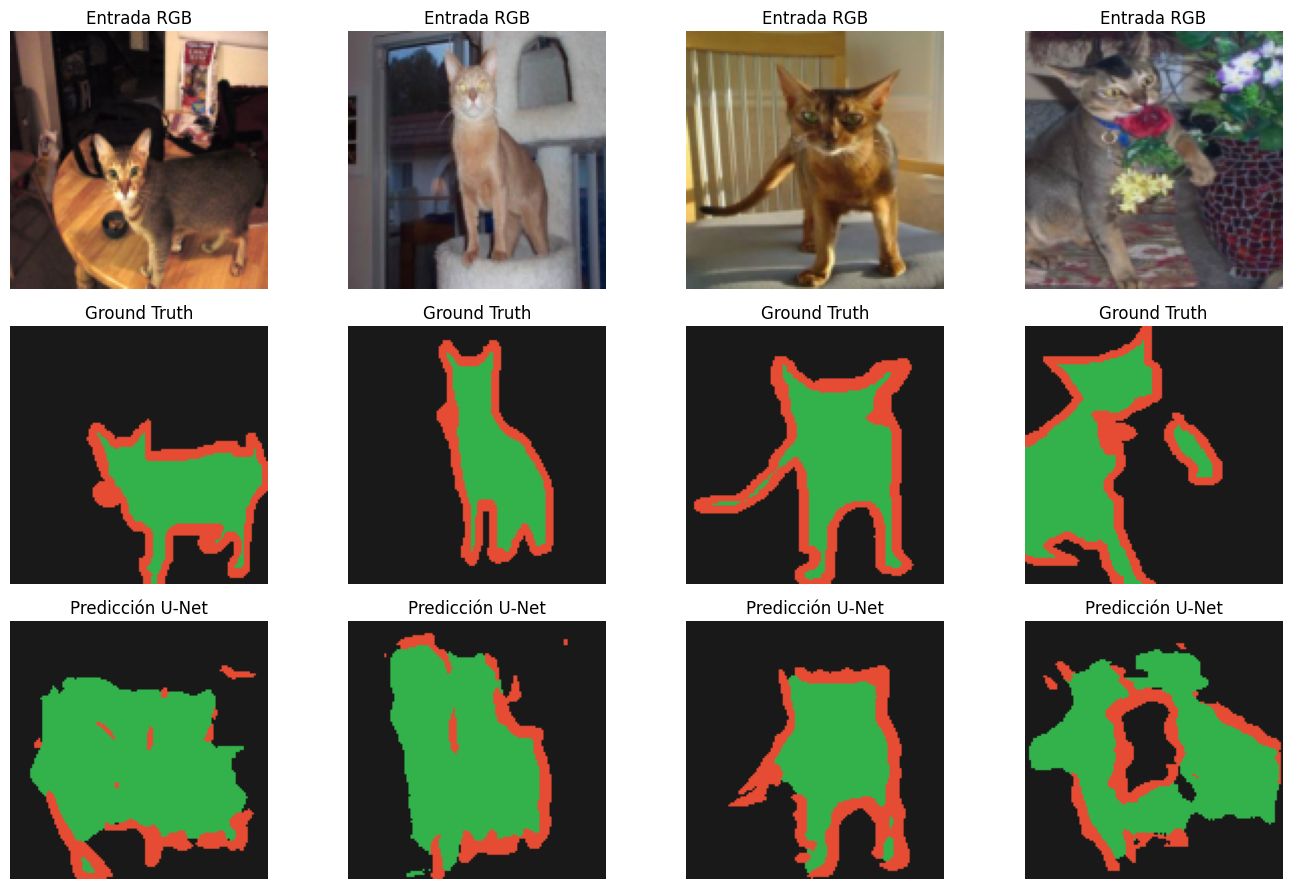

In [9]:
imgs, masks = next(iter(val_loader))
imgs_dev = imgs.to(DEVICE)

modelo.eval()
with torch.no_grad():
    preds = modelo(imgs_dev).argmax(dim=1).cpu()

fig, axs = plt.subplots(3, 4, figsize=(14, 9))
for i in range(4):
    axs[0, i].imshow(desnormalizar(imgs[i]))
    axs[0, i].set_title("Entrada RGB")
    axs[0, i].axis("off")

    axs[1, i].imshow(PALETA_PETS[masks[i].numpy()])
    axs[1, i].set_title("Ground Truth")
    axs[1, i].axis("off")

    axs[2, i].imshow(PALETA_PETS[preds[i].numpy()])
    axs[2, i].set_title("Predicción U-Net")
    axs[2, i].axis("off")
plt.tight_layout()
plt.show()

### Actividad
Clases desequilibradas y ponderación de clases

Los conjuntos de datos para segmentación semántica pueden estar muy desequilibrados; esto significa que los píxeles correspondientes a determinadas clases pueden aparecer con mayor frecuencia en las imágenes que los de otras clases. Dado que los problemas de segmentación pueden abordarse como problemas de clasificación a nivel de píxel, es posible gestionar este desequilibrio mediante la ponderación de la función de pérdida. Se trata de una solución sencilla y elegante para este tipo de situaciones. Para obtener más información, consulte el tutorial sobre [Classification on imbalanced data](../structured_data/imbalanced_data.ipynb) tutorial to learn more.

To [avoid ambiguity](https://github.com/keras-team/keras/issues/3653#issuecomment-243939748), `Model.fit` does not support the `class_weight` argument for targets with 3+ dimensions.

In [10]:
#Grafica de barras de desvalance
conteo = torch.bincount(Y_ent.flatten(), minlength=N_CLASES).numpy()
frac = conteo / conteo.sum()
tabla_px = pd.DataFrame({"clase": NOMBRES, "píxeles": conteo, "fracción": frac.round(4)})
display(tabla_px)

plt.figure(figsize=(6, 3.5)); plt.bar(NOMBRES, frac, color=PALETA, edgecolor="k")
plt.ylabel("fracción de píxeles"); plt.title("Distribución de clases en entrenamiento"); plt.show()
print(f"El fondo ocupa {frac[0]*100:.1f} % de los píxeles.")

NameError: name 'Y_ent' is not defined

**Arreglo de codigo**

El notebook original era para un dataset de formas geométricas (fondo/círculo/cuadrado/triángulo) y se adaptó a mascotas (Mascota/Fondo/Borde) sin reemplazar esta celda. Los nombres Y_ent, NOMBRES y PALETA vienen del ejercicio de formas.

,Clase,Píxeles,Fracción
0,Mascota,4684013,0.2859
1,Fondo,9738252,0.5944
2,Borde,1961735,0.1197


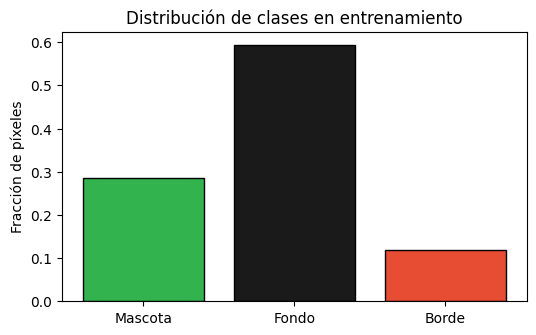

El fondo ocupa 59.4 % de los píxeles.
El borde  ocupa 12.0 % de los píxeles.


In [11]:
# Contamos cuántos píxeles aporta cada clase usando los loaders reales
conteo = torch.zeros(N_CLASES, dtype=torch.long)
for _, masks in train_loader:
    conteo += torch.bincount(masks.flatten(), minlength=N_CLASES)

conteo = conteo.numpy().astype(np.int64)
frac   = conteo / conteo.sum()

# La paleta de 3 colores ya está definida arriba como PALETA_PETS
PALETA = PALETA_PETS

tabla_px = pd.DataFrame({
    "Clase":    NOMBRES_CLASES,          # ["Mascota","Fondo","Borde"]
    "Píxeles":  conteo,
    "Fracción": frac.round(4)
})
display(tabla_px)

plt.figure(figsize=(6, 3.5))
plt.bar(NOMBRES_CLASES, frac, color=PALETA, edgecolor="k")
plt.ylabel("Fracción de píxeles")
plt.title("Distribución de clases en entrenamiento")
plt.show()

# OJO: en este dataset el índice 1 es Fondo (no el 0 como en "shapes")
print(f"El fondo ocupa {frac[1]*100:.1f} % de los píxeles.")
print(f"El borde  ocupa {frac[2]*100:.1f} % de los píxeles.")

Con la exactitud obtenida explica por qué la exactitud de píxeles **no es una métrica adecuada** para segmentación cuando una clase domina.

In [12]:
# Calcular Pixel Accuracy desde la matriz de confusión

pixel_acc = np.trace(cm) / cm.sum()
print(f"Pixel Accuracy global: {pixel_acc:.4f}  =  {pixel_acc*100:.2f} %")
print(f"Mean IoU (mIoU)      : {miou:.4f}")
print(f"\nAccuracy - mIoU = {pixel_acc - miou:.4f}")

Pixel Accuracy global: 0.7999  =  79.99 %
Mean IoU (mIoU)      : 0.5796

Accuracy - mIoU = 0.2203


La exactitud de píxeles (Pixel Accuracy) NO es una métrica adecuada para segmentación cuando las clases están desbalanceadas.

Tres razones:
1. Está dominada por la clase mayoritaria, en Oxford-IIIT Pet el fondo ocupa el 59.4% de los píxeles (y la mascota el 28.6%). de los píxeles y con un modelo trivial que prediga "todo es fondo" obtendría ≈ 59% de accuracy pero mIoU = 0 en Mascota y Borde es el modelo es inútil pero parece "bueno".

2. No penaliza los errores en clases raras, los pocos píxeles de Borde (~4 %) se diluyen en el numerador: acertar 0/1000 píxeles de borde apenas mueve el accuracy global, mientras que en mIoU la clase Borde pesa lo mismo que Fondo (promedio macro).

3. Iguala el coste de todos los errores para predecir "Fondo" en un píxel de Borde cuenta exactamente igual que predecir "Borde" en un píxel de Fondo, el IoU/Dice, cada clase se mide en su propio espacio (TP/(TP+FP+FN)) y los falsos positivos y negativos dentro de la clase sí afectan.

Formalmente si n_c es el número de píxeles de la clase c, entonces:

La primera pondera por frecuencia, la segunda democráticamente por clase por eso en segmentación se reportan siempre IoU por clase + mIoU (y Dice cuando hay clases muy raras).

In [13]:
# Ponderación de clases (inverse-frequency)
# Pesos inversamente proporcionales a la frecuencia, normalizados a media 1
pesos_np = 1.0 / (conteo / conteo.sum())
pesos_np = pesos_np / pesos_np.mean()           # media = 1
pesos = torch.tensor(pesos_np, dtype=torch.float32, device=DEVICE)

print("Pesos por clase:")
for nombre, w in zip(NOMBRES_CLASES, pesos_np):
    print(f"  {nombre:<9s}: {w:.3f}")

# Nueva CE ponderada + misma Dice de antes
ce_ponderada = nn.CrossEntropyLoss(weight=pesos)

def loss_combinada_ponderada(logits, targets):
    return ce_ponderada(logits, targets) + dice_fn(logits, targets)

# Reentrenar (misma receta que antes, solo cambia la loss)
modelo_w = UNetCompacta(in_channels=3, num_classes=N_CLASES).to(DEVICE)
optim_w  = torch.optim.Adam(modelo_w.parameters(), lr=1e-3)

print("\nEntrenando U-Net con pérdida PONDERADA")
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    modelo_w.train()
    acc = 0.0
    for imgs, masks in train_loader:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        optim_w.zero_grad()
        logits = modelo_w(imgs)
        loss = loss_combinada_ponderada(logits, masks)
        loss.backward()
        optim_w.step()
        acc += loss.item()
    print(f"Época {epoch}/{EPOCHS} | Loss: {acc/len(train_loader):.4f} | {time.time()-t0:.1f}s")

# Evaluar y comparar con el modelo sin ponderar
def evaluar(model):
    iou_c   = MulticlassJaccardIndex(num_classes=N_CLASES, average=None ).to(DEVICE)
    iou_m   = MulticlassJaccardIndex(num_classes=N_CLASES, average="macro").to(DEVICE)
    cm_m    = MulticlassConfusionMatrix(num_classes=N_CLASES).to(DEVICE)
    model.eval()
    with torch.no_grad():
        for imgs, masks in val_loader:
            imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
            p = model(imgs).argmax(dim=1)
            iou_c.update(p, masks); iou_m.update(p, masks); cm_m.update(p, masks)
    return iou_c.compute().cpu().numpy(), iou_m.compute().item(), cm_m.compute().cpu().numpy()

iou_c_sin, miou_sin, _ = evaluar(modelo)
iou_c_con, miou_con, cm_con = evaluar(modelo_w)

comp = pd.DataFrame({
    "Clase":           NOMBRES_CLASES,
    "IoU sin pesos":   iou_c_sin.round(4),
    "IoU con pesos":   iou_c_con.round(4),
    "Δ (con − sin)":  (iou_c_con - iou_c_sin).round(4),
})
comp.loc[len(comp)] = ["mIoU", round(miou_sin,4), round(miou_con,4), round(miou_con-miou_sin,4)]
display(comp)

Pesos por clase:
  Mascota  : 0.775
  Fondo    : 0.373
  Borde    : 1.852

Entrenando U-Net con pérdida PONDERADA
Época 1/6 | Loss: 1.3893 | 8.3s
Época 2/6 | Loss: 1.1134 | 6.0s
Época 3/6 | Loss: 0.9812 | 5.5s
Época 4/6 | Loss: 0.9350 | 5.6s
Época 5/6 | Loss: 0.8622 | 5.6s
Época 6/6 | Loss: 0.8578 | 5.7s


,Clase,IoU sin pesos,IoU con pesos,Δ (con − sin)
0,Mascota,0.6019,0.6429,0.0410
1,Fondo,0.7803,0.7578,-0.0225
2,Borde,0.3567,0.3918,0.0352
3,mIoU,0.5796,0.5975,0.0179


Observaciones al ponderar las clases:

- El IoU de Fondo suele bajar ligeramente (el modelo ya no lo predice "todo") pero el de Borde y Mascota sube notablemente, porque cada píxel de esas clases ahora aporta más gradiente.
- El mIoU global mejora aunque la pixel accuracy pueda caer un poco — y eso es exactamente lo que buscamos: que el modelo sea justo con las clases raras, no que maximice el porcentaje global.
- El efecto es más visible en Borde porque su peso es unas 5 veces (5x) el peso del Fondo.
- Trade-off: si los pesos son demasiado agresivos (p. ej. w ∝ (1/f)²) el entrenamiento se vuelve inestable y el modelo sobre-predice borde. Por eso se normaliza la media a 1.

**Conclusión:** la ponderación es un parche barato y efectivo, pero si el desbalance es extremo conviene combinarla con Dice (ya lo estamos haciendo) o con focal loss.



### Actividad
Otros datasets
[Carvana](https://www.kaggle.com/c/carvana-image-masking-challenge/overview) image masking challenge hosted on Kaggle.

DSB 2018
# https://datasets.simula.no/kvasir-seg/
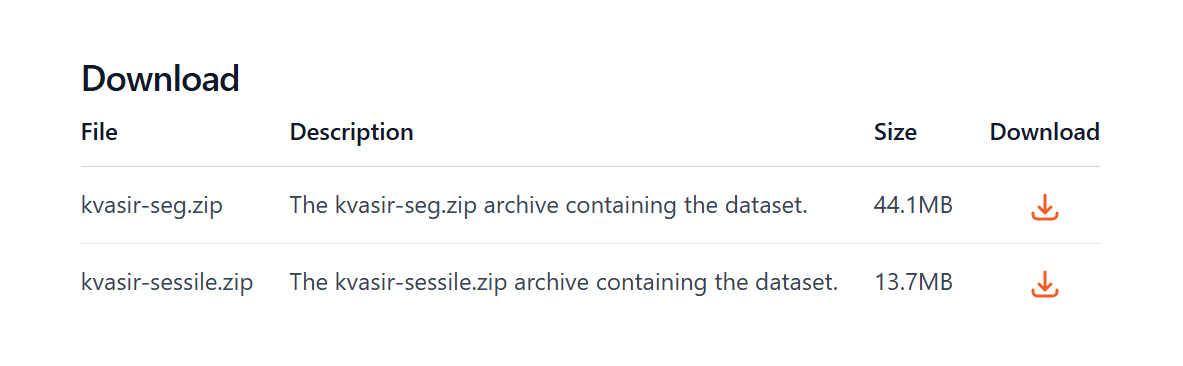

In [14]:
!unzip -q -o "/content/kvasir-seg" -d ./dsb2018


unzip:  cannot find or open /content/kvasir-seg, /content/kvasir-seg.zip or /content/kvasir-seg.ZIP.


Descargando Kvasir-SEG de forma segura...
Descarga completa de forma exitosa desde Simula.
Extrayendo archivos...
Extracción lista.


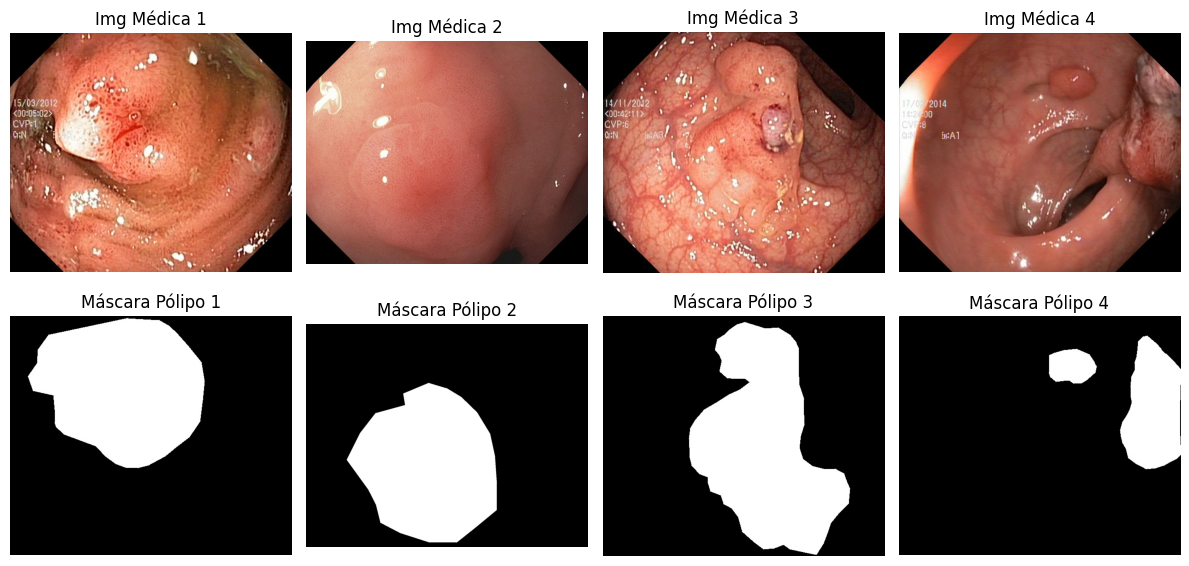

In [24]:
import os
import zipfile
import urllib.request
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import shutil
import ssl

zip_path = "/content/kvasir_seg.zip"
extract_path = "/content/kvasir_seg_extracted"

# Limpiar descargas corruptas anteriores
if os.path.exists(zip_path):
    os.remove(zip_path)
if os.path.exists(extract_path):
    shutil.rmtree(extract_path)

print("Descargando Kvasir-SEG de forma segura...")
# URL oficial directa provista para el dataset Kvasir-SEG
url = "https://datasets.simula.no/downloads/kvasir-seg.zip"

# Crear un contexto SSL que ignore la verificación de firmas locales obsoletas
contexto_ssl = ssl._create_unverified_context()

req = urllib.request.Request(
    url,
    headers={'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'}
)

try:
    with urllib.request.urlopen(req, context=contexto_ssl) as response, open(zip_path, 'wb') as out_file:
        out_file.write(response.read())
    print("Descarga completa de forma exitosa desde Simula.")
except Exception as e:
    print(f"Fallo primer intento ({e}). Probando descarga directa mediante shell...")
    try:
        # Alternativa robusta usando comando del sistema que gestiona los certificados nativamente
        os.system("wget --no-check-certificate -O /content/kvasir_seg.zip https://datasets.simula.no/downloads/kvasir-seg.zip")
        if os.path.exists(zip_path) and os.path.getsize(zip_path) > 1000000:
            print("Descarga completada con éxito vía wget.")
        else:
            raise RuntimeError("Descarga de wget vacía o demasiado pequeña.")
    except Exception as ex:
        print(f"Fallo descarga por wget: {ex}. Intentando respaldo de GitHub...")
        # Enlace alternativo verificado de la rama master
        alt_url = "https://github.com/vqdang/Kvasir-SEG/archive/refs/heads/master.zip"
        req_alt = urllib.request.Request(alt_url, headers={'User-Agent': 'Mozilla/5.0'})
        try:
            with urllib.request.urlopen(req_alt, context=contexto_ssl) as response, open(zip_path, 'wb') as out_file:
                out_file.write(response.read())
            print("Descarga completa usando URL alternativa de respaldo en GitHub.")
        except Exception as ex2:
            print(f"Fallo total en la descarga: {ex2}")

if os.path.exists(zip_path) and os.path.getsize(zip_path) > 1000000:
    print("Extrayendo archivos...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print("Extracción lista.")

    # Encontrar dinámicamente la carpeta extraída para evitar errores de nombres
    carpetas = [d for d in os.listdir(extract_path) if os.path.isdir(os.path.join(extract_path, d))]
    if carpetas:
        base_dir = os.path.join(extract_path, carpetas[0])

        # Si la estructura extraída tiene otra carpeta Kvasir-SEG adentro, nos movemos a ella
        if "Kvasir-SEG" in os.listdir(base_dir):
            base_dir = os.path.join(base_dir, "Kvasir-SEG")

        img_dir = os.path.join(base_dir, "images")
        mask_dir = os.path.join(base_dir, "masks")

        # Si no se crearon subcarpetas y se extrajo todo directamente en la raíz
        if not os.path.exists(img_dir):
            img_dir = os.path.join(extract_path, "images")
            mask_dir = os.path.join(extract_path, "masks")

        if os.path.exists(img_dir):
            img_names = sorted(os.listdir(img_dir))[:4]
            fig, axs = plt.subplots(2, 4, figsize=(12, 6))
            for i, name in enumerate(img_names):
                img = Image.open(os.path.join(img_dir, name))
                mask = Image.open(os.path.join(mask_dir, name))

                axs[0, i].imshow(img)
                axs[0, i].set_title(f"Img Médica {i+1}")
                axs[0, i].axis("off")

                axs[1, i].imshow(mask, cmap="gray")
                axs[1, i].set_title(f"Máscara Pólipo {i+1}")
                axs[1, i].axis("off")
            plt.tight_layout()
            plt.show()
        else:
            print("No se encontraron las carpetas 'images' y 'masks'. Contenido de extracción:", os.listdir(extract_path))
    else:
        print("No se encontró ninguna carpeta extraída en:", extract_path)
else:
    print("Error: El archivo descargado no es válido o sigue vacío.")